# Etapa 3 — Construção e avaliação dos classificadores

**Disciplina:** Inteligência Artificial — Profa. Cristiane Neri Nobre
**Trabalho em competição:** Detecção de Intrusão em Redes (NSL-KDD, base atualizada)
**Equipe:** _preencher_
**Etapa 3 — entrega 21/11/2026**

**Objetivo.** Treinar e comparar ao menos três algoritmos vistos na disciplina sobre as melhores
combinações de pré-processamento da Etapa 2, ajustar hiperparâmetros por validação cruzada
agrupada no treino, tentar subir o F1-macro sem vazamento e congelar a configuração final em
`results/final_config.json`, que o notebook 04 usará para gerar a submissão.

**Resumo dos resultados**

Todas as medidas são F1-macro de CV agrupada por duplicata, só no treino, calculado em **todas as
linhas** do fold, como a métrica oficial. Os 1.702 grupos de linhas idênticas com rótulos opostos
limitam esse valor a 0,905 mesmo para um classificador perfeito; os modelos ficam perto de 0,88.

- **Oito algoritmos comparados** (5-fold): HGB 0,8821, RF 0,8808, XGB 0,8799, Extra Trees 0,8774,
  MLP 0,8711, KNN 0,8624, Árvore de Decisão 0,8403, Naive Bayes 0,7662. Os ensembles de árvores
  dominam; a árvore única e o Naive Bayes sofrem com o ruído de rótulo e com atributos correlacionados.
- **Ajuste de hiperparâmetros** (busca aleatória com o mesmo protocolo): nenhum ganho na primeira
  rodada; os padrões já estavam no platô.
- **Tentativas de ganho:** atributos derivados por linha (pioram um pouco nos três modelos), busca
  ampliada no HGB (melhor sorteio 0,8828), média de 5 sementes, votos e dois algoritmos fora da
  disciplina (LightGBM e CatBoost).
- **Finalistas em CV 3×5 (15 candidatos):** a maior média é a do voto HGB + XGB + RF
  (0,8826 ± 0,0029), mas onze candidatos ficam a menos de 1 dp dele. Pelo critério declarado
  (empate vai para o mais simples), o escolhido é o **HGB da busca ampliada, com F1-macro
  0,8819 ± 0,0030** (precisão em `anomaly` 0,759, recall 0,798): um modelo único, da disciplina,
  9 vezes mais barato que o voto.
- **De onde vêm os erros:** no OOF, 1.706 dos 1.851 erros caem nas 3.730 linhas com rótulo
  contraditório. Fora delas, o modelo erra 145 de 66.103 linhas (F1-macro 0,983).
- **Configuração congelada** em `results/final_config.json`: HGB com categorias e NaN nativos,
  remoção dos conflitos no treino (`drop_inconsistent`) e limiar de decisão ajustado por OOF.

**Índice**
0. Configuração e política de dados
1. Protocolo experimental e critério de escolha
2. Comparação de oito algoritmos
3. Ajuste de hiperparâmetros
4. Tentativas de ganho adicional
5. Finalistas em CV repetida (3×5)
6. Tabela comparativa consolidada
7. Análise dos erros do modelo escolhido (OOF)
8. Escolha e congelamento do modelo final
9. Conclusões

## 0. Configuração e política de dados

Bibliotecas, semente global e o registro de experimentos. Como na Etapa 2, `ExperimentLog` guarda
cada configuração em `results/experiments.csv` com uma chave (hash) do modelo, do
pré-processamento e da versão da base. Reexecutar o notebook lê do registro o que já foi
calculado. Os mesmos experimentos podem ser rodados fora do notebook com
`python tools/rodar_experimentos.py etapa3` e `etapa3_extra`: script e notebook montam os
modelos pelo mesmo módulo (`nslkdd.modeling`), então compartilham o cache.

**Tempo de execução.** Calcular os 135 experimentos desta etapa do zero leva cerca de 2 horas
em 16 núcleos (muito mais nos 2 núcleos do Colab). Com `RECALCULAR = False`, os resultados
vêm do registro e o notebook roda em poucos minutos, mesmo com versões de bibliotecas
diferentes das nossas: se a chave exata não bater (uma versão nova pode acrescentar
parâmetros ao modelo), o registro é consultado por uma chave estável, que só considera os
parâmetros diferentes do padrão. Com `RECALCULAR = True`, toda validação cruzada é refeita.

In [1]:
RECALCULAR = False  # True = refaz todas as validações cruzadas (~2 h em 16 núcleos)

import json
import warnings; warnings.filterwarnings("ignore")
from datetime import date
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn, imblearn
import xgboost, lightgbm, catboost
from IPython.display import display
from nslkdd import ExperimentLog, build_pipeline, config, cross_val_proba, load_train
from nslkdd.data import conflict_mask, evaluation_mask
from nslkdd.decision import best_threshold, macro_f1_curve
from nslkdd.evaluation import binary_metrics, validation_report
from nslkdd.modeling import (N_SEARCH, N_SEARCH_HGB2, SEARCH, SEARCH_HGB2, SEEDS, catalog,
                             new_finalists, round2_best, run_catalog, run_finalists,
                             screen_engineering, tuned, EXTERNAL, SEARCH_EXT,
                             N_SEARCH_EXT, run_external, external_finalists)
from nslkdd.models import SoftVote, make_model
from nslkdd.preprocessing import FeatureBuilder
from nslkdd.search import FOLD_JOBS, threads

X, y, groups = load_train()
log = ExperimentLog(recompute=RECALCULAR)
np.random.seed(config.RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
config.FIGURES.mkdir(parents=True, exist_ok=True)

best = json.loads((config.RESULTS / "melhores_configuracoes.json").read_text(encoding="utf-8"))
cat = catalog(best)

print({m.__name__: m.__version__ for m in (np, pd, sklearn, imblearn, xgboost, lightgbm, catboost)})
print("RANDOM_STATE =", config.RANDOM_STATE, "| versão da base:", log.data_version)
print("X:", X.shape, "| classes:", y.value_counts().to_dict())

{'numpy': '2.5.4', 'pandas': '3.0.6', 'sklearn': '1.9.1', 'imblearn': '0.14.2', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10'}
RANDOM_STATE = 42 | versão da base: db8fb3ac
X: (69833, 41) | classes: {'normal': 65754, 'anomaly': 4079}


**Política de dados.**
- Só `treino.csv` é usado. O teste (`teste_sem_rotulo.csv`) só entra no notebook 04, uma única
  vez, depois do congelamento feito na Seção 8. `data/raw/` (NSL-KDD original) não é usada.
- `X` tem só os 41 atributos de rede. As colunas de vazamento (`score_ids_legado`,
  `tipo_alerta_soc`, `tempo_resposta_analista_min`) e as 5 cópias derivadas não entram.
- Todo passo que aprende algo (limpeza de rótulos, imputação, codificação, escala, seleção) está
  dentro do `Pipeline` montado por `build_pipeline`, ajustado só nos folds de treino. O limiar de
  decisão também é escolhido só com previsões out-of-fold do treino.

## 1. Protocolo experimental e critério de escolha

**Validação.** O mesmo protocolo da Etapa 2: `StratifiedGroupKFold` com 5 folds, agrupado por
duplicata (cópias nunca ficam uma no treino e outra na validação). A métrica principal é o
F1-macro em **todas as linhas** do fold de validação, cópias e conflitos incluídos, porque é assim
que a métrica oficial é calculada no teste. Os 1.702 grupos de linhas idênticas com rótulos
opostos (3.730 linhas) limitam esse valor a 0,905 mesmo para um classificador perfeito (que
escolhesse o melhor rótulo em cada conflito); os modelos reais ficam perto de 0,88. O F1-macro nas
linhas únicas e sem conflito (`f1_macro_clean`) aparece só como contraste: mostra quanto do erro
é ruído de rótulo, mas não decide nada e não estima a nota.

**Limiar de decisão.** Cada fold é pontuado com um limiar escolhido nas previsões out-of-fold dos
outros folds (todas as linhas). No modelo final, `ThresholdClassifier` faz o mesmo: aprende o
limiar por OOF dentro do próprio treino, em todas as linhas.

**Pré-processamento por algoritmo** (herdado da Etapa 2, `melhores_configuracoes.json`). Cada
família recebe a configuração vencedora da sua busca; os algoritmos sem busca própria herdam a da
família mais próxima:

In [2]:
display(pd.DataFrame(cat).T.fillna("—"))

,redundancy,domain,imputation,scaling,log_transform,service_encoding,categorical_encoding,balancing,reduction,reduction_k
DT,none,nan,median,none,False,onehot,onehot,none,none,—
RF,none,nan,median,none,False,onehot,onehot,none,none,—
ET,none,nan,median,none,False,onehot,onehot,none,none,—
HGB_native,drop_inconsistent,nan,none,none,False,ordinal,ordinal,none,—,—
XGB,drop_inconsistent,nan,none,none,False,ordinal,ordinal,none,—,—
MLP,none,nan,median,standard,True,onehot,—,none,none,—
KNN,none,nan,median,standard,True,onehot,—,none,kbest_f,30
NB,none,nan,median,standard,True,onehot,—,none,none,—


**Critério de escolha do modelo final, declarado antes de ver os resultados:**
1. maior F1-macro médio na CV agrupada **repetida 3×5** (15 folds);
2. diferença menor que 1 desvio-padrão (entre folds) é empate;
3. no empate, vence o modelo mais simples e explicável (menos membros, menos passos).

Acurácia nunca é critério: com 16 conexões normais para cada ataque (65.754 × 4.079), um
classificador que diz sempre `normal` já tem 94% de acurácia e F1-macro de 0,48.

## 2. Comparação de oito algoritmos

Primeiro, cada algoritmo com hiperparâmetros padrão razoáveis (catálogo `make_model`) e o seu
pré-processamento. Os oito cobrem as famílias vistas na disciplina:

| Sigla | Algoritmo | Família |
|---|---|---|
| DT | Árvore de Decisão (CART) | árvore única |
| RF | Random Forest | bagging de árvores |
| ET | Extra Trees | bagging de árvores aleatorizadas |
| HGB_native | Histogram Gradient Boosting (categorias e NaN nativos) | boosting |
| XGB | XGBoost | boosting |
| MLP | Rede neural (perceptron multicamadas) | redes neurais |
| KNN | k vizinhos mais próximos | baseado em instâncias |
| NB | Naive Bayes gaussiano | probabilístico |

In [3]:
catalog_results = run_catalog(log, X, y, groups, best, verbose=False)
board = log.leaderboard("etapa3")[["model", "f1_macro_mean", "f1_macro_std", "f1_macro_05_mean",
                                   "f1_anomaly_mean", "precision_anomaly_mean",
                                   "recall_anomaly_mean", "balanced_accuracy_mean",
                                   "threshold_mean", "cv_seconds"]]
display(board.reset_index(drop=True).round(4))

,model,f1_macro_mean,f1_macro_std,f1_macro_05_mean,f1_anomaly_mean,precision_anomaly_mean,recall_anomaly_mean,balanced_accuracy_mean,threshold_mean,cv_seconds
0,HGB_native,0.8821,0.0009,0.8801,0.7784,0.7565,0.8017,0.8928,0.110,14.3
1,RF,0.8808,0.0018,0.8729,0.7760,0.7534,0.8002,0.8920,0.308,33.2
2,XGB,0.8799,0.0008,0.8775,0.7742,0.7506,0.7995,0.8915,0.140,15.7
3,ET,0.8774,0.0028,0.8723,0.7695,0.7539,0.7857,0.8849,0.354,42.5
4,MLP,0.8711,0.0044,0.8692,0.7576,0.7456,0.7705,0.8771,0.344,24.3
5,KNN,0.8624,0.0058,0.8606,0.7410,0.7352,0.7472,0.8653,0.398,12.8
6,DT,0.8403,0.0024,0.8403,0.7015,0.6333,0.7867,0.8792,0.360,14.8
7,NB,0.7662,0.0292,0.7557,0.5696,0.4596,0.7578,0.8502,0.970,10.6


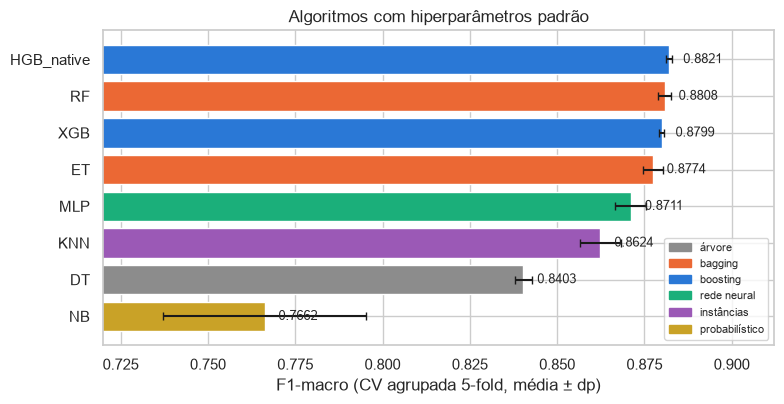

In [4]:
FAMILY = {"DT": "árvore", "RF": "bagging", "ET": "bagging", "HGB_native": "boosting",
          "XGB": "boosting", "MLP": "rede neural", "KNN": "instâncias", "NB": "probabilístico"}
PALETTE = {"árvore": "#8c8c8c", "bagging": "#eb6834", "boosting": "#2a78d6",
           "rede neural": "#1baf7a", "instâncias": "#9b59b6", "probabilístico": "#c9a227"}
b = board.sort_values("f1_macro_mean")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(b["model"], b["f1_macro_mean"], xerr=b["f1_macro_std"],
        color=[PALETTE[FAMILY[m]] for m in b["model"]], capsize=3)
for i, v in enumerate(b["f1_macro_mean"]):
    ax.text(v + 0.004, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(round(b["f1_macro_mean"].min() - 0.05, 2), b["f1_macro_mean"].max() + 0.03)
ax.set_xlabel("F1-macro (CV agrupada 5-fold, média ± dp)")
ax.set_title("Algoritmos com hiperparâmetros padrão")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PALETTE.values()]
ax.legend(handles, PALETTE.keys(), loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES / "mod_algoritmos.png", dpi=150, bbox_inches="tight")
plt.show()

**O que se conclui.**
- **Os ensembles de árvores dominam.** HGB (0,8821), RF (0,8808) e XGB (0,8799) ficam
  praticamente empatados no topo, à frente de ET (0,8774). Os atributos do KDD são contagens e
  taxas com limiares nítidos (ex.: `serror_rate` alto = varredura SYN), exatamente o que cortes
  de árvore capturam.
- **A árvore única (0,8403) perde 4 pontos para os ensembles.** Sem a média de bagging ou a
  correção sequencial do boosting, ela se ajusta ao ruído de rótulo (1.702 grupos contraditórios)
  e tem alta variância. Numa escala em que o teto é 0,905, é uma distância grande.
- **MLP (0,8711) e KNN (0,8624)** dependem de escala e de distâncias. Mesmo com `log1p` +
  padronização, a mistura de 67 colunas one-hot de `service` com taxas contínuas pesa contra
  eles.
- **Naive Bayes (0,7662 ± 0,029)** é o pior e o mais instável: supõe atributos independentes e
  gaussianos, e os atributos de taxa são fortemente correlacionados (ex.: `serror_rate`,
  `srv_serror_rate`, `dst_host_serror_rate`) e concentrados em 0 e 1.
- O limiar ajustado fica abaixo de 0,5 em todos menos o NB (0,11–0,40): com a classe `anomaly`
  minoritária, baixar o corte troca alguns falsos positivos por mais acertos de ataque e aumenta
  o F1-macro. No HGB e no XGB, que treinam sem os conflitos, o limiar cai mais (0,11 e 0,14): nos
  grupos empatados da validação, prever `anomaly` rende mais F1-macro que prever `normal`.
- A coluna `f1_macro_05_mean` (limiar fixo em 0,5) mostra o ganho do limiar ajustado: de 0,002
  no HGB a 0,008 no RF.

Seguem para o ajuste de hiperparâmetros os três melhores (HGB, RF, XGB) e o MLP, que representa
as redes neurais citadas no enunciado.

## 3. Ajuste de hiperparâmetros

**Busca aleatória** (`ParameterSampler`, semente 42) com o mesmo protocolo de CV agrupada e o
mesmo registro. Não usamos `GridSearchCV` direto porque ele não aplica o limiar cruzado (cada
fold pontuado com o limiar aprendido nos outros) e não grava no registro comum. Espaços de busca:

In [5]:
display(pd.DataFrame({m: {k: str(v) for k, v in s.items()} for m, s in SEARCH.items()}).T.fillna("—"))
print("Sorteios por modelo:", N_SEARCH)

,max_iter,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,n_estimators,max_depth,subsample,colsample_bytree,min_child_weight,max_features,class_weight,hidden_layer_sizes,alpha,learning_rate_init
HGB_native,"[200, 300, 500, 800]","[0.02, 0.04, 0.06, 0.1]","[15, 31, 63]","[5, 10, 20, 40]","[0.0, 0.1, 1.0, 5.0]",—,—,—,—,—,—,—,—,—,—
XGB,—,"[0.02, 0.05, 0.1]",—,—,—,"[300, 600, 1000]","[4, 6, 7, 9]","[0.7, 0.8, 1.0]","[0.5, 0.7, 1.0]","[1, 3, 5]",—,—,—,—,—
RF,—,—,—,"[1, 2, 4]",—,"[300, 500]",—,—,—,—,"['sqrt', 0.3, 0.5]","[None, 'balanced_subsample']",—,—,—
MLP,—,—,—,—,—,—,—,—,—,—,—,—,"[(64,), (128, 64), (256, 128)]","[0.0001, 0.001, 0.01]","[0.0005, 0.001]"


Sorteios por modelo: {'HGB_native': 12, 'XGB': 12, 'RF': 6, 'MLP': 6}


In [6]:
search_rows, hps = [], {}
for name in SEARCH:
    hps[name], trials = tuned(log, name, cat[name], X, y, groups, verbose=False)
    for hp, r in trials:
        search_rows.append({"modelo": name, "hiperparâmetros": json.dumps(hp),
                            "f1_macro": r["f1_macro_mean"], "dp": r["f1_macro_std"],
                            "segundos": r["cv_seconds"]})
search = pd.DataFrame(search_rows)
summary = search.groupby("modelo", sort=False).agg(sorteios=("f1_macro", "size"),
                                                    pior=("f1_macro", "min"),
                                                    melhor=("f1_macro", "max"))
summary["padrão (Seção 2)"] = [catalog_results[m]["f1_macro_mean"] for m in summary.index]
summary["ganho do tuning"] = (summary["melhor"] - summary["padrão (Seção 2)"]).round(4)
display(summary)
for name, hp in hps.items():
    print(f"{name:11s} melhor configuração: {hp}")

,sorteios,pior,melhor,padrão (Seção 2),ganho do tuning
modelo,,,,,
HGB_native,12,0.8754,0.8817,0.8821,-0.0004
XGB,12,0.8755,0.8800,0.8799,0.0001
RF,6,0.8786,0.8806,0.8808,-0.0002
MLP,6,0.8663,0.8721,0.8711,0.0010


HGB_native  melhor configuração: {'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 800, 'learning_rate': 0.04, 'l2_regularization': 1.0}
XGB         melhor configuração: {'subsample': 0.8, 'n_estimators': 1000, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.5}
RF          melhor configuração: {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.5, 'class_weight': None}
MLP         melhor configuração: {'learning_rate_init': 0.001, 'hidden_layer_sizes': (256, 128), 'alpha': 0.0001}


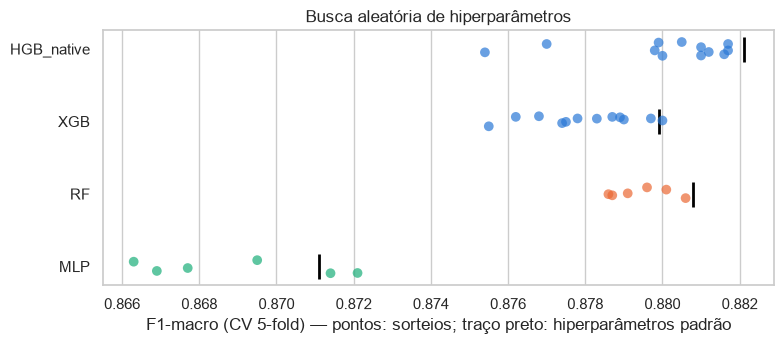

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = list(SEARCH)
sns.stripplot(data=search, x="f1_macro", y="modelo", order=order, size=7, alpha=0.7,
              hue="modelo", palette=[PALETTE[FAMILY[m]] for m in order], legend=False, ax=ax)
for i, m in enumerate(order):
    ax.plot(catalog_results[m]["f1_macro_mean"], i, marker="|", color="black", ms=18, mew=2)
ax.set_xlabel("F1-macro (CV 5-fold) — pontos: sorteios; traço preto: hiperparâmetros padrão")
ax.set_ylabel("")
ax.set_title("Busca aleatória de hiperparâmetros")
fig.tight_layout()
fig.savefig(config.FIGURES / "mod_busca.png", dpi=150, bbox_inches="tight")
plt.show()

**O que se conclui.** O ajuste de hiperparâmetros não rendeu, e é importante dizer isso:
- **HGB:** o melhor sorteio (0,8817) fica um pouco abaixo do padrão (0,8821). O padrão do
  catálogo já estava no platô.
- **RF e XGB:** o melhor sorteio empata com o padrão (RF 0,8806 vs 0,8808; XGB 0,8800 vs 0,8799).
  Com 6 a 12 sorteios, a busca não encontrou nada melhor que o padrão, que já vinha de valores
  consagrados para esses algoritmos.
- **MLP:** 0,8721 vs 0,8711, também dentro do ruído.
- A dispersão entre sorteios (0,006 no HGB) é maior que a diferença entre os melhores. Os
  hiperparâmetros importam para fugir de configurações ruins (ex.: poucas iterações com taxa de
  aprendizado baixa), mas não diferenciam as boas.

## 4. Tentativas de ganho adicional

Como é uma competição, testamos mais quatro ideias para subir o F1-macro, todas sem tocar no
teste e dentro do pipeline:
1. **Engenharia de atributos** (`FeatureBuilder`): razões e interações calculadas por linha a
   partir dos 41 atributos de rede. É uma regra fixa, sem parâmetros aprendidos, então aplicá-la
   ao teste não usa informação dele.
2. **Busca ampliada no HGB:** o melhor modelo é também o mais rápido (cerca de 17 s por CV), o que
   permite uma segunda busca mais larga, incluindo amostragem de colunas (`max_features`).
3. **Algoritmos fora da disciplina:** LightGBM e CatBoost (Seção 4.3).
4. **Média de sementes e votos** entre os melhores modelos (Seção 5).

### 4.1 Engenharia de atributos

Atributos criados (todos de uma mesma linha; ausentes propagam como NaN):

In [8]:
display(pd.DataFrame({"atributo": FeatureBuilder.NAMES, "definição": [
    "log1p(src_bytes) − log1p(dst_bytes): direção do fluxo",
    "log1p(src_bytes / (duration + 1)): taxa de envio",
    "1 se src_bytes = dst_bytes = 0 (conexão sem payload, típica de varredura)",
    "srv_count / (count + 1)",
    "serror_rate × count: nº de conexões com erro SYN na janela",
    "rerror_rate × count: nº de conexões rejeitadas na janela",
    "same_srv_rate × count", "diff_srv_rate × count",
    "dst_host_srv_count / (dst_host_count + 1)",
    "dst_host_serror_rate × dst_host_count", "dst_host_rerror_rate × dst_host_count",
    "dst_host_same_srv_rate × dst_host_count"]}))

,atributo,definição
0,bytes_ratio_log,log1p(src_bytes) − log1p(dst_bytes): direção d...
1,src_bytes_per_sec_log,log1p(src_bytes / (duration + 1)): taxa de envio
2,zero_bytes,1 se src_bytes = dst_bytes = 0 (conexão sem pa...
3,srv_count_ratio,srv_count / (count + 1)
4,serror_count,serror_rate × count: nº de conexões com erro S...
5,rerror_count,rerror_rate × count: nº de conexões rejeitadas...
6,same_srv_count,same_srv_rate × count
7,diff_srv_count,diff_srv_rate × count
8,dst_host_srv_ratio,dst_host_srv_count / (dst_host_count + 1)
9,dst_host_serror_count,dst_host_serror_rate × dst_host_count


A ideia: as taxas do KDD (`serror_rate` etc.) perdem a escala. Uma taxa de 100% de erro SYN em 2
conexões e em 500 conexões são coisas muito diferentes, mas uma árvore precisa de vários cortes
combinados em `serror_rate` e `count` para separá-las. O produto entrega isso pronto. Cada modelo
usa os hiperparâmetros da Seção 3, com e sem os atributos novos:

In [9]:
eng = screen_engineering(log, X, y, groups, best, hps, verbose=False)
eng_table = pd.DataFrame([{"modelo": m, "sem atributos": eng[(m, False)]["f1_macro_mean"],
                           "dp (sem)": eng[(m, False)]["f1_macro_std"],
                           "com atributos": eng[(m, True)]["f1_macro_mean"],
                           "dp (com)": eng[(m, True)]["f1_macro_std"]}
                          for m in ("HGB_native", "XGB", "RF")]).set_index("modelo")
eng_table["ganho"] = (eng_table["com atributos"] - eng_table["sem atributos"]).round(4)
display(eng_table)

,sem atributos,dp (sem),com atributos,dp (com),ganho
modelo,,,,,
HGB_native,0.8817,0.0011,0.8808,0.0008,-0.0009
XGB,0.8800,0.0013,0.8783,0.0011,-0.0017
RF,0.8806,0.0014,0.8805,0.0019,-0.0001


**O que se conclui.** Nenhum modelo melhora com os atributos novos: HGB (−0,0009), XGB (−0,0017)
e RF (−0,0001) ficam iguais ou um pouco piores. Colunas redundantes diluem a amostragem de
atributos (`colsample_bytree` no XGB, `max_features` no RF), e as árvores desses modelos já
combinavam taxa e contagem sozinhas. A ideia segue para a busca ampliada e para a CV repetida da
Seção 5, para não descartá-la com base em uma única partição.

### 4.2 Busca ampliada no HGB

Espaço mais largo que o da Seção 3 (mais iterações, folhas maiores, amostragem de colunas), com
20 sorteios sem e 20 com os atributos derivados:

In [10]:
display(pd.DataFrame({k: str(v) for k, v in SEARCH_HGB2.items()}, index=["valores"]).T)
round2 = round2_best(log, X, y, groups, best)
hgb2 = {e: hp for e, (hp, _) in round2.items()}
r2 = pd.DataFrame([{"atributos": e, **hp, "f1_macro": r["f1_macro_mean"], "dp": r["f1_macro_std"]}
                   for e, (_, trials) in round2.items() for hp, r in trials])
display(r2.sort_values("f1_macro", ascending=False).head(8).reset_index(drop=True))
display(r2.groupby("atributos")["f1_macro"].describe()[["count", "mean", "std", "min", "max"]])

,valores
max_iter,"[500, 800, 1200, 1600]"
learning_rate,"[0.03, 0.05, 0.08]"
max_leaf_nodes,"[15, 31, 63, 127]"
min_samples_leaf,"[3, 5, 10, 20]"
l2_regularization,"[0.0, 0.1, 1.0, 5.0]"
max_features,"[0.5, 0.7, 1.0]"


,atributos,min_samples_leaf,max_leaf_nodes,max_iter,max_features,learning_rate,l2_regularization,f1_macro,dp
0,False,20,63,500,0.7,0.08,0.0,0.8828,0.0008
1,False,10,63,500,1.0,0.05,0.0,0.8827,0.0012
2,False,20,31,500,1.0,0.08,0.1,0.8823,0.0019
3,True,5,31,800,0.5,0.03,0.0,0.8822,0.0015
4,True,10,15,800,0.7,0.08,0.0,0.8822,0.0007
5,False,10,63,1200,1.0,0.08,0.1,0.8821,0.0012
6,True,20,63,1600,1.0,0.05,0.1,0.8821,0.0012
7,False,5,31,800,0.5,0.03,0.0,0.8821,0.0012


,count,mean,std,min,max
atributos,,,,,
False,20.0,0.88148,0.000676,0.8803,0.8828
True,20.0,0.88127,0.000633,0.8802,0.8822


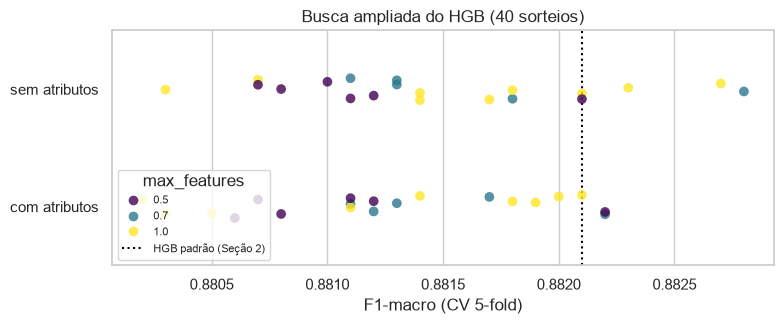

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.stripplot(data=r2, x="f1_macro", y=r2["atributos"].map({False: "sem atributos",
                                                           True: "com atributos"}),
              hue="max_features", palette="viridis", size=7, alpha=0.8, ax=ax)
ax.axvline(catalog_results["HGB_native"]["f1_macro_mean"], color="black", ls=":",
           label="HGB padrão (Seção 2)")
ax.set_xlabel("F1-macro (CV 5-fold)")
ax.set_ylabel("")
ax.set_title("Busca ampliada do HGB (40 sorteios)")
ax.legend(title="max_features", fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(config.FIGURES / "mod_busca_hgb2.png", dpi=150, bbox_inches="tight")
plt.show()

**O que se conclui.** O melhor sorteio, sem atributos derivados (`min_samples_leaf=20`,
`max_leaf_nodes=63`, `max_iter=500`, `learning_rate=0,08`, `max_features=0,7`), chega a
0,8828 ± 0,0008. Ele combina mais regularização por folha (20 exemplos no mínimo) com uma taxa de
aprendizado maior e amostragem de colunas. Mas a média dos sorteios (0,8815) fica abaixo do HGB
padrão (0,8821): escolher o máximo de 20 sorteios dá vantagem a quem teve sorte no particionamento
da semente 42. Com atributos, a distribuição é praticamente a mesma (média de 0,8813). Os melhores
de cada grupo seguem para a confirmação em CV 3×5.

### 4.3 Algoritmos fora da disciplina: LightGBM e CatBoost

Por ser uma competição, testamos também dois algoritmos que não foram vistos na disciplina, mas
são referência em dados tabulares. O enunciado exige ao menos 3 algoritmos da disciplina
(requisito já cumprido nas Seções 2 e 3) e não proíbe outros.
- **LightGBM:** boosting por histogramas com crescimento das árvores *por folha* (expande sempre
  a folha que mais reduz a perda), amostragem de linhas e colunas e categorias nativas.
- **CatBoost:** boosting com árvores simétricas (o mesmo corte em todo o nível) e codificação
  ordenada das categorias por estatísticas do alvo, calculada sem olhar o próprio exemplo.

Os dois recebem o mesmo pré-processamento do HGB (limpeza de rótulos `drop_inconsistent`, NaN
nativo) e tratam `protocol_type`, `service` e `flag` como categóricos (adaptador
`NativeCategoricalBoost`). Protocolo idêntico: padrão do catálogo, depois busca aleatória
(20 sorteios no LightGBM; 8 no CatBoost, que é cerca de 5 vezes mais lento).

In [12]:
display(pd.DataFrame({m: {k: str(v) for k, v in sp.items()} for m, sp in SEARCH_EXT.items()}).T)
ext_defaults, ext_searches = run_external(log, X, y, groups, best, verbose=False)
ext_hps = {n: hp for n, (hp, _) in ext_searches.items()}
ext_table = pd.DataFrame([{"modelo": n, "sorteios": len(ext_searches[n][1]),
                           "padrão": ext_defaults[n]["f1_macro_mean"],
                           "pior sorteio": min(r["f1_macro_mean"] for _, r in ext_searches[n][1]),
                           "melhor sorteio": max(r["f1_macro_mean"] for _, r in ext_searches[n][1]),
                           "segundos por CV": ext_defaults[n]["cv_seconds"]}
                          for n in EXTERNAL]).set_index("modelo")
ext_table.loc["HGB (busca 2, referência)"] = [N_SEARCH_HGB2, catalog_results["HGB_native"]["f1_macro_mean"],
                                              r2[~r2["atributos"]]["f1_macro"].min(),
                                              r2[~r2["atributos"]]["f1_macro"].max(),
                                              catalog_results["HGB_native"]["cv_seconds"]]
display(ext_table)
for n, hp in ext_hps.items():
    print(f"{n:9s} melhor configuração: {hp}")

,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,iterations,depth,l2_leaf_reg
LGBM,"[300, 600, 1000, 1500]","[0.02, 0.05, 0.08]","[15, 31, 63, 127]","[5, 10, 20, 40]","[0.7, 0.8, 1.0]","[0.5, 0.7, 1.0]","[0.0, 0.1, 1.0, 5.0]",NaN,NaN,NaN
CatBoost,NaN,"[0.03, 0.05, 0.08, 0.12]",NaN,NaN,NaN,NaN,NaN,"[500, 1000, 1500]","[4, 6, 8]","[1, 3, 10]"


,sorteios,padrão,pior sorteio,melhor sorteio,segundos por CV
modelo,,,,,
LGBM,20.0,0.8818,0.8754,0.8822,17.6
CatBoost,8.0,0.8760,0.8674,0.8777,88.4
"HGB (busca 2, referência)",20.0,0.8821,0.8803,0.8828,14.3


LGBM      melhor configuração: {'subsample': 0.8, 'reg_lambda': 0.0, 'num_leaves': 63, 'n_estimators': 1000, 'min_child_samples': 5, 'learning_rate': 0.08, 'colsample_bytree': 1.0}
CatBoost  melhor configuração: {'learning_rate': 0.05, 'l2_leaf_reg': 3, 'iterations': 500, 'depth': 8}


**O que se conclui.**
- **LightGBM:** o padrão (0,8818) já empata com o HGB padrão (0,8821). A busca encontra 0,8822
  (`num_leaves=63`, 1.000 iterações, taxa 0,08), empatado com o HGB. Faz sentido: os dois são
  boosting por histogramas e diferem em detalhes (crescimento por folha, amostragem de linhas e
  colunas).
- **CatBoost:** é o pior dos boosting (padrão 0,8760; melhor sorteio 0,8777) e o mais lento (cerca
  de 5 vezes o tempo do HGB). As árvores simétricas usam o mesmo corte em todo um nível, o que é
  uma boa regularização em bases pequenas, mas limita a captura de regras muito específicas, como
  as dos ataques raros. Ele também treina com os conflitos removidos e sofre menos com isso, mas a
  codificação por estatísticas do alvo é afetada pelo ruído de rótulo restante.
- Os melhores de cada um seguem para a CV 3×5, sozinhos e em votos com o HGB.

## 5. Finalistas em CV repetida (3×5)

Uma CV de 5 folds com uma semente só tem desvio-padrão de 0,001 a 0,003, da mesma ordem que as
diferenças entre os candidatos. Escolher o máximo de 40 sorteios nessas condições tende a premiar
a sorte do particionamento. Por isso, os finalistas são reavaliados com **3 repetições** da CV
agrupada (sementes 42, 43 e 44; 15 folds), e é essa medida que decide (critério da Seção 1).

Finalistas:
- os quatro algoritmos da Seção 3 com os melhores hiperparâmetros (HGB, XGB, RF, MLP) e o voto
  suave HGB + XGB + RF (média das probabilidades, cada membro com seu pré-processamento);
- os candidatos da Seção 4: HGB com atributos, os melhores da busca ampliada (sem e com
  atributos), a **média de 5 sementes** do melhor HGB (com `max_features = 0,7`, para que as
  sementes gerem modelos diferentes) e o **voto** entre os dois HGB da busca ampliada;
- os algoritmos fora da disciplina (Seção 4.3): LightGBM e CatBoost ajustados, e os votos
  HGB + LightGBM, HGB + CatBoost e HGB + LightGBM + CatBoost.

In [13]:
clean = cat["HGB_native"]["redundancy"]
first_round = {n: build_pipeline(make_model(n, threads(n), **hps[n]), **cat[n]) for n in hps}
vote3 = SoftVote([(n.lower(), first_round[n]) for n in ("HGB_native", "XGB", "RF")])
candidates = [(n, p, {"redundancy": clean, "repeticoes": 3})
              for n, p in [*first_round.items(), ("Voto HGB+XGB+RF", vote3)]]
candidates += new_finalists(best, hps, hgb2)
candidates += external_finalists(best, hgb2, ext_hps)
final_results = run_finalists(log, X, y, groups, candidates, verbose=False)

final_board = pd.DataFrame([{"modelo": n, **{k: r[k] for k in [
    "f1_macro_mean", "f1_macro_std", "f1_macro_05_mean", "f1_macro_clean_mean", "f1_anomaly_mean",
    "precision_anomaly_mean", "recall_anomaly_mean", "balanced_accuracy_mean", "threshold_mean",
    "cv_seconds"]}} for n, r in final_results.items()])
# Empate exato na média (4 casas): fica à frente o de menor desvio-padrão (mais estável).
final_board = final_board.sort_values(["f1_macro_mean", "f1_macro_std"],
                                      ascending=[False, True]).reset_index(drop=True)
leader = final_board.iloc[0]
final_board["empata com o 1º"] = (leader["f1_macro_mean"] - final_board["f1_macro_mean"]
                                  < leader["f1_macro_std"])
display(final_board.round(4))

,modelo,f1_macro_mean,f1_macro_std,f1_macro_05_mean,f1_macro_clean_mean,f1_anomaly_mean,precision_anomaly_mean,recall_anomaly_mean,balanced_accuracy_mean,threshold_mean,cv_seconds,empata com o 1º
0,Voto HGB+XGB+RF,0.8826,0.0029,0.8793,0.9821,0.7794,0.7568,0.8035,0.8937,0.2160,663.3,True
1,Voto HGB + LightGBM,0.8822,0.0030,0.8801,0.9821,0.7786,0.7587,0.7996,0.8919,0.0867,137.9,True
2,Voto HGB busca 2 ± atributos,0.8821,0.0027,0.8799,0.9821,0.7783,0.7584,0.7993,0.8917,0.0853,117.4,True
3,Voto HGB + LightGBM + CatBoost,0.8821,0.0029,0.8793,0.9820,0.7784,0.7588,0.7991,0.8916,0.1713,276.0,True
4,"HGB busca 2, 5 sementes",0.8820,0.0027,0.8797,0.9819,0.7782,0.7588,0.7987,0.8915,0.0620,224.2,True
5,HGB busca 2,0.8819,0.0030,0.8796,0.9817,0.7779,0.7588,0.7982,0.8912,0.0440,75.5,True
6,HGB busca 2 + atributos,0.8818,0.0030,0.8796,0.9819,0.7777,0.7589,0.7976,0.8909,0.0833,77.0,True
7,LightGBM,0.8815,0.0029,0.8786,0.9812,0.7772,0.7589,0.7965,0.8904,0.0407,63.4,True
8,Voto HGB + CatBoost,0.8813,0.0027,0.8790,0.9812,0.7767,0.7594,0.7950,0.8897,0.2093,326.0,True
9,RF,0.8812,0.0031,0.8779,0.9801,0.7768,0.7551,0.7999,0.8919,0.3627,618.6,True


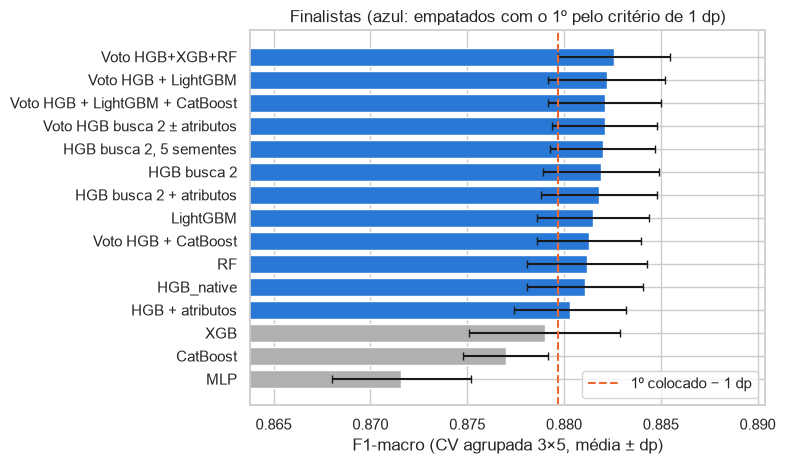

In [14]:
fb = final_board.sort_values("f1_macro_mean")
fig, ax = plt.subplots(figsize=(8, 4.8))
colors = ["#2a78d6" if t else "#b0b0b0" for t in fb["empata com o 1º"]]
ax.barh(fb["modelo"], fb["f1_macro_mean"], xerr=fb["f1_macro_std"], color=colors, capsize=3)
ax.axvline(leader["f1_macro_mean"] - leader["f1_macro_std"], color="#eb6834", ls="--",
           label="1º colocado − 1 dp")
pad = 2 * fb["f1_macro_std"].max()
ax.set_xlim(fb["f1_macro_mean"].min() - pad, fb["f1_macro_mean"].max() + pad)
ax.set_xlabel("F1-macro (CV agrupada 3×5, média ± dp)")
ax.set_title("Finalistas (azul: empatados com o 1º pelo critério de 1 dp)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(config.FIGURES / "mod_finalistas.png", dpi=150, bbox_inches="tight")
plt.show()

**Aplicando o critério da Seção 1.** Entre os empatados com o 1º (diferença < 1 dp), vence o mais
simples. A complexidade é medida, nesta ordem, por: (1) número de modelos que precisam ser
treinados (um voto de três modelos custa três vezes mais e é mais difícil de explicar); (2) passos
extras no pipeline (atributos derivados); (3) algoritmo fora da disciplina, que tem menos
respaldo no material. Persistindo o empate, decide a maior média e, depois, o menor desvio.

In [15]:
def members(name):
    if name.startswith("Voto"):
        return name.count("+") + 1 + name.count("±")
    return len(SEEDS) if "sementes" in name else 1


tied = final_board[final_board["empata com o 1º"]].copy()
tied["modelos treinados"] = tied["modelo"].map(members)
tied["atributos derivados"] = tied["modelo"].str.contains("atributos")
tied["fora da disciplina"] = tied["modelo"].str.contains("LightGBM|CatBoost")
tied = tied.sort_values(["modelos treinados", "atributos derivados", "fora da disciplina",
                         "f1_macro_mean", "f1_macro_std"],
                        ascending=[True, True, True, False, True])
display(tied[["modelo", "f1_macro_mean", "f1_macro_std", "modelos treinados",
              "atributos derivados", "fora da disciplina", "cv_seconds"]].reset_index(drop=True))
chosen = tied.iloc[0]["modelo"]
print("Escolhido pelo critério:", chosen)

,modelo,f1_macro_mean,f1_macro_std,modelos treinados,atributos derivados,fora da disciplina,cv_seconds
0,HGB busca 2,0.8819,0.0030,1,False,False,75.5
1,RF,0.8812,0.0031,1,False,False,618.6
2,HGB_native,0.8811,0.0030,1,False,False,70.8
3,LightGBM,0.8815,0.0029,1,False,True,63.4
4,HGB busca 2 + atributos,0.8818,0.0030,1,True,False,77.0
5,HGB + atributos,0.8803,0.0029,1,True,False,85.1
6,Voto HGB + LightGBM,0.8822,0.0030,2,False,True,137.9
7,Voto HGB + CatBoost,0.8813,0.0027,2,False,True,326.0
8,Voto HGB busca 2 ± atributos,0.8821,0.0027,2,True,False,117.4
9,Voto HGB+XGB+RF,0.8826,0.0029,3,False,False,663.3


Escolhido pelo critério: HGB busca 2


**O que se conclui.**
- **Onze candidatos ficam a menos de 1 dp do 1º.** O voto HGB + XGB + RF tem a maior média
  (0,8826 ± 0,0029), mas o HGB da busca ampliada fica a 0,0007 dele (0,8819 ± 0,0030), uma
  diferença quatro vezes menor que o desvio entre folds. Pelo critério, vence o mais simples: o
  **HGB da busca ampliada**, um modelo único da disciplina, sem passos extras, que treina em cerca
  de 1/9 do tempo do voto.
- **O ganho do HGB da busca ampliada sobre o da primeira rodada (0,8811) está dentro do ruído.**
  Além disso, a busca usou a partição da semente 42, que também entra na CV 3×5, o que dá um leve
  viés otimista a favor dele.
- **Algoritmos fora da disciplina:** o LightGBM ajustado (0,8815) empata com o HGB, mas não o
  supera; os dois são boosting por histogramas, com ideias muito parecidas. O CatBoost fica atrás
  (0,8770), fora do empate.
- **Atributos derivados não se confirmam:** na CV 3×5, o HGB com atributos (0,8803) fica abaixo do
  HGB sem eles (0,8811), e o da busca ampliada com atributos (0,8818) empata com o sem (0,8819).
- **Ensembles não ajudam de forma mensurável:** média de sementes (0,8820), voto entre HGBs
  (0,8821), HGB + LightGBM (0,8822), HGB + CatBoost (0,8813), HGB + LightGBM + CatBoost (0,8821) e
  HGB + XGB + RF (0,8826, com 9 vezes o custo) ficam todos dentro do ruído do modelo único. Os
  modelos fortes erram nos mesmos exemplos, então tirar a média corrige pouco.
- **XGB, CatBoost e MLP ficam fora do empate** (0,8790, 0,8770 e 0,8716). O RF (0,8812) entra no
  empate na CV 3×5.
- **Contraste sem conflitos:** a coluna `f1_macro_clean_mean` (mesmos modelos e limiares, só nas
  linhas únicas e sem rótulo contraditório) fica entre 0,962 e 0,982 e ordena os modelos quase do
  mesmo jeito. A diferença para os ~0,88 da métrica oficial é o efeito dos conflitos, que pesa
  igual para todos os modelos. Ela não estima a nota e não decide nada.
- **Custo do rigor:** sozinhas, sem nenhum atributo de rede, as colunas de vazamento
  (`score_ids_legado` etc.) já alcançam F1-macro de 0,889 na mesma métrica (Etapa 1), acima de
  todos os modelos de tráfego. Abrir mão delas é a decisão correta: são posteriores ao evento e não
  existiriam no momento de classificar uma conexão real.

## 6. Tabela comparativa consolidada

Linhas = estratégia de pré-processamento × algoritmo; colunas = métricas de CV agrupada. A
primeira tabela é a comparação dos oito algoritmos (5-fold, hiperparâmetros padrão); a segunda,
os finalistas (3×5). As duas vão para `results/` em CSV e Markdown, prontas para o relatório.

In [16]:
def describe_prep(p):
    """Resumo legível do pré-processamento de uma linha da tabela."""
    imput = "NaN nativo" if p.get("imputation") == "none" else p.get("imputation")
    service = "nativa" if p.get("service_encoding") == "ordinal" else p.get("service_encoding")
    parts = [f"redundância: {p.get('redundancy', 'none')}", f"ausentes: {imput}",
             f"service: {service}"]
    if p.get("scaling", "none") != "none":
        parts.append(("log1p + " if p.get("log_transform") else "") + p["scaling"])
    if p.get("reduction", "none") != "none":
        parts.append(p["reduction"] + (f" k={p['reduction_k']}" if "reduction_k" in p else ""))
    if p.get("engineered"):
        parts.append("+ atributos derivados")
    return "; ".join(parts)


METRIC_COLS = {"f1_macro_mean": "F1-macro", "f1_macro_std": "dp", "f1_anomaly_mean": "F1 anomaly",
               "f1_normal_mean": "F1 normal", "precision_anomaly_mean": "precisão anomaly",
               "recall_anomaly_mean": "recall anomaly", "balanced_accuracy_mean": "acur. balanceada",
               "accuracy_mean": "acurácia", "cv_seconds": "tempo (s)"}

table_algos = pd.DataFrame([{"algoritmo": n, "pré-processamento": describe_prep(cat[n]),
                             **{v: catalog_results[n][k] for k, v in METRIC_COLS.items()}}
                            for n in cat]).sort_values("F1-macro", ascending=False)

eng_prep = describe_prep({**cat["HGB_native"], "engineered": True})
prep_of = {n: describe_prep(cat[n]) for n in hps}
prep_of.update({"Voto HGB+XGB+RF": "cada membro com o seu", "HGB + atributos": eng_prep,
                "HGB busca 2": describe_prep(cat["HGB_native"]),
                "HGB busca 2 + atributos": eng_prep,
                "HGB busca 2, 5 sementes": describe_prep(cat["HGB_native"]),
                "Voto HGB busca 2 ± atributos": "cada membro com o seu",
                "LightGBM": describe_prep(cat["HGB_native"]),
                "CatBoost": describe_prep(cat["HGB_native"]),
                "Voto HGB + LightGBM": "cada membro com o seu",
                "Voto HGB + CatBoost": "cada membro com o seu",
                "Voto HGB + LightGBM + CatBoost": "cada membro com o seu"})
table_final = pd.DataFrame([{"modelo": n, "pré-processamento": prep_of[n],
                             **{v: r[k] for k, v in METRIC_COLS.items()}}
                            for n, r in final_results.items()]).sort_values("F1-macro",
                                                                            ascending=False)


def to_markdown(df):
    """Markdown simples (sem depender do pacote tabulate)."""
    def fmt(v):
        if isinstance(v, float):
            return f"{v:.4f}" if abs(v) < 10 else f"{v:.0f}"
        return str(v)
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


for name, t in [("etapa3_algoritmos", table_algos), ("etapa3_finalistas", table_final)]:
    t.to_csv(config.RESULTS / f"tabela_{name}.csv", index=False)
    (config.RESULTS / f"tabela_{name}.md").write_text(to_markdown(t), encoding="utf-8")
display(table_algos.reset_index(drop=True).round(4))
display(table_final.reset_index(drop=True).round(4))

,algoritmo,pré-processamento,F1-macro,dp,F1 anomaly,F1 normal,precisão anomaly,recall anomaly,acur. balanceada,acurácia,tempo (s)
0,HGB_native,redundância: drop_inconsistent; ausentes: NaN ...,0.8821,0.0009,0.7784,0.9858,0.7565,0.8017,0.8928,0.9733,14.3
1,RF,redundância: none; ausentes: median; service: ...,0.8808,0.0018,0.7760,0.9856,0.7534,0.8002,0.8920,0.9730,33.2
2,XGB,redundância: drop_inconsistent; ausentes: NaN ...,0.8799,0.0008,0.7742,0.9855,0.7506,0.7995,0.8915,0.9728,15.7
3,ET,redundância: none; ausentes: median; service: ...,0.8774,0.0028,0.7695,0.9854,0.7539,0.7857,0.8849,0.9725,42.5
4,MLP,redundância: none; ausentes: median; service: ...,0.8711,0.0044,0.7576,0.9847,0.7456,0.7705,0.8771,0.9712,24.3
5,KNN,redundância: none; ausentes: median; service: ...,0.8624,0.0058,0.7410,0.9838,0.7352,0.7472,0.8653,0.9695,12.8
6,DT,redundância: none; ausentes: median; service: ...,0.8403,0.0024,0.7015,0.9791,0.6333,0.7867,0.8792,0.9609,14.8
7,NB,redundância: none; ausentes: median; service: ...,0.7662,0.0292,0.5696,0.9629,0.4596,0.7578,0.8502,0.9318,10.6


,modelo,pré-processamento,F1-macro,dp,F1 anomaly,F1 normal,precisão anomaly,recall anomaly,acur. balanceada,acurácia,tempo (s)
0,Voto HGB+XGB+RF,cada membro com o seu,0.8826,0.0029,0.7794,0.9859,0.7568,0.8035,0.8937,0.9734,663.3
1,Voto HGB + LightGBM,cada membro com o seu,0.8822,0.0030,0.7786,0.9859,0.7587,0.7996,0.8919,0.9734,137.9
2,Voto HGB busca 2 ± atributos,cada membro com o seu,0.8821,0.0027,0.7783,0.9859,0.7584,0.7993,0.8917,0.9734,117.4
3,Voto HGB + LightGBM + CatBoost,cada membro com o seu,0.8821,0.0029,0.7784,0.9859,0.7588,0.7991,0.8916,0.9734,276.0
4,"HGB busca 2, 5 sementes",redundância: drop_inconsistent; ausentes: NaN ...,0.8820,0.0027,0.7782,0.9859,0.7588,0.7987,0.8915,0.9734,224.2
5,HGB busca 2,redundância: drop_inconsistent; ausentes: NaN ...,0.8819,0.0030,0.7779,0.9858,0.7588,0.7982,0.8912,0.9734,75.5
6,HGB busca 2 + atributos,redundância: drop_inconsistent; ausentes: NaN ...,0.8818,0.0030,0.7777,0.9858,0.7589,0.7976,0.8909,0.9734,77.0
7,LightGBM,redundância: drop_inconsistent; ausentes: NaN ...,0.8815,0.0029,0.7772,0.9858,0.7589,0.7965,0.8904,0.9733,63.4
8,Voto HGB + CatBoost,cada membro com o seu,0.8813,0.0027,0.7767,0.9858,0.7594,0.7950,0.8897,0.9733,326.0
9,RF,redundância: none; ausentes: median; service: ...,0.8812,0.0031,0.7768,0.9857,0.7551,0.7999,0.8919,0.9731,618.6


**Qual pré-processamento ajuda qual algoritmo, e por quê.**
- **A limpeza de rótulos (`drop_inconsistent`) ajuda o boosting, mas não o bagging.** No HGB, ela
  vale cerca de 0,004 de F1-macro (Etapa 2), mais de 1 dp. O boosting ajusta cada árvore aos
  erros das anteriores e acaba perseguindo exemplos com rótulo trocado. O RF tira a média de
  árvores treinadas em amostras diferentes, o que já dilui o ruído.
- **Escala e `log1p` importam para MLP e KNN, não para árvores.** Árvores são invariantes a
  transformações monotônicas: só a ordem dos valores importa para os cortes. No MLP, o `log1p`
  comprime as caudas de `src_bytes`/`dst_bytes`, que sem ele dominariam os gradientes.
- **Codificação de `service`:** o HGB usa as categorias de forma nativa (agrupa serviços num
  único corte). RF, MLP e KNN usam one-hot, que não impõe ordem falsa entre serviços.
- **Ausentes:** só HGB e XGB tratam NaN de forma nativa (aprendem para que lado da divisão vai o
  ausente). Os demais precisam de imputação pela mediana.
- **Redução:** nenhuma técnica passou da regra na Etapa 2 (a seleção por árvores empatou com não
  reduzir no RF). O `SelectKBest` do KNN serve para tirar dimensões irrelevantes do cálculo de
  distâncias. O PCA perdeu em todos os testes da Etapa 2.
- **Balanceamento:** nenhum. O limiar de decisão ajustado por OOF (0,04–0,36 nos finalistas) faz o
  papel do balanceamento sem criar exemplos sintéticos.
- **A acurácia esconde as diferenças:** ela vai de 93,2% (NB) a 97,3% (HGB), enquanto o F1-macro
  vai de 0,77 a 0,88. A árvore única tem 96,1% de acurácia, mas só 63% de precisão em `anomaly`.

## 7. Análise dos erros do modelo escolhido (OOF)

Previsões out-of-fold do modelo escolhido (CV agrupada 5-fold, semente 42) mostram *onde* ele
erra. Esta seção é só diagnóstica: não altera a escolha nem os hiperparâmetros. O limiar abaixo é
escolhido no OOF inteiro (todas as linhas), que é o que `ThresholdClassifier` fará no treino
completo do notebook 04. Os erros são separados em dois grupos: os que caem nas linhas com rótulo
contraditório (inevitáveis: a mesma linha tem os dois rótulos e recebe uma só previsão) e os
demais, que são os erros de fato do modelo.

Modelo analisado: HGB busca 2


Limiar escolhido no OOF: 0.03
F1-macro (OOF, todas as linhas): 0.8828
Acurácia balanceada: 0.8935



              precision    recall  f1-score   support

      normal     0.9877    0.9841    0.9859     65754
     anomaly     0.7578    0.8029    0.7797      4079

    accuracy                         0.9735     69833
   macro avg     0.8727    0.8935    0.8828     69833
weighted avg     0.9743    0.9735    0.9739     69833



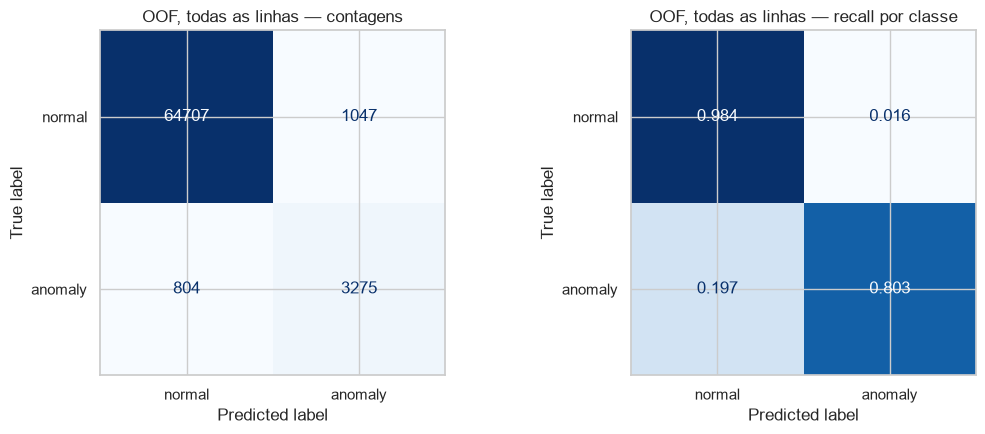

Contraste, mesmo limiar, linhas únicas e sem conflito: F1-macro 0.9824
Erros: 1851 | em linhas com rótulo contraditório: 1706 de 3730 | no resto: 145 de 66103
F1-macro só nas linhas sem conflito (com as cópias): 0.9828


In [17]:
final_pipe = {n: p for n, p, _ in candidates}[chosen]
print("Modelo analisado:", chosen)
oof, oof_fold = cross_val_proba(final_pipe, X, y, groups, n_jobs=FOLD_JOBS)
is_pos = y.to_numpy() == config.POSITIVE
conflict = conflict_mask(groups, y)
mask = evaluation_mask(groups, y)  # linhas únicas e sem conflito: só contraste
thr = best_threshold(oof, is_pos)
pred = np.where(oof >= thr, config.POSITIVE, "normal")
print(f"Limiar escolhido no OOF: {thr:.2f}")
validation_report(y, pred, title="OOF, todas as linhas", save_as="mod_confusao_oof.png")
plt.show()
wrong = pred != y.to_numpy()
print(f"Contraste, mesmo limiar, linhas únicas e sem conflito: F1-macro "
      f"{binary_metrics(is_pos[mask], pred[mask] == config.POSITIVE)['f1_macro']:.4f}")
print(f"Erros: {wrong.sum()} | em linhas com rótulo contraditório: {(wrong & conflict).sum()} "
      f"de {conflict.sum()} | no resto: {(wrong & ~conflict).sum()} de {(~conflict).sum()}")
no_conflict = binary_metrics(is_pos[~conflict], pred[~conflict] == config.POSITIVE)["f1_macro"]
print(f"F1-macro só nas linhas sem conflito (com as cópias): {no_conflict:.4f}")

Curva do F1-macro em função do limiar: mostra quanto a escolha do corte importa e se o máximo é
estável (platô) ou um pico isolado.

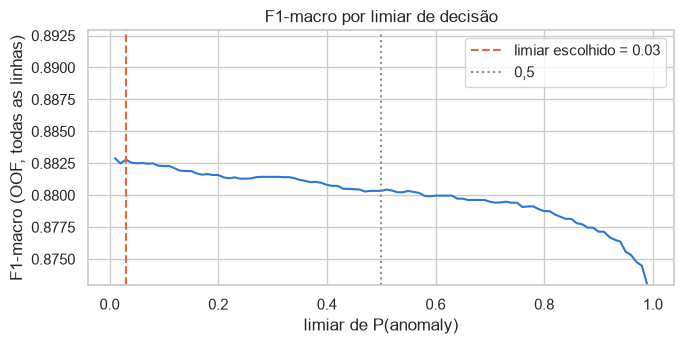

F1 no limiar escolhido: 0.8828 | em 0,5: 0.8803 | faixa com F1 a até 0,002 do máximo: 0.01–0.39


In [18]:
grid = np.linspace(0.01, 0.99, 99)
curve = macro_f1_curve(oof, is_pos, grid)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(grid, curve, color="#2a78d6")
ax.axvline(thr, color="#eb6834", ls="--", label=f"limiar escolhido = {thr:.2f}")
ax.axvline(0.5, color="#8c8c8c", ls=":", label="0,5")
ax.set_ylim(max(curve.max() - 0.1, curve.min()), curve.max() + 0.01)
ax.set_xlabel("limiar de P(anomaly)")
ax.set_ylabel("F1-macro (OOF, todas as linhas)")
ax.set_title("F1-macro por limiar de decisão")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "mod_limiar.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"F1 no limiar escolhido: {curve[np.argmin(abs(grid - thr))]:.4f} | em 0,5: "
      f"{curve[np.argmin(abs(grid - 0.5))]:.4f} | faixa com F1 a até 0,002 do máximo: "
      f"{grid[curve >= curve.max() - 0.002].min():.2f}–{grid[curve >= curve.max() - 0.002].max():.2f}")

Onde estão os erros do modelo? Fora das linhas com rótulo contraditório, falsos negativos
(ataques que passam como normais) e falsos positivos, por `service` e `flag`, comparados com a
distribuição dessas linhas:

In [19]:
ev = X[~conflict].assign(classe=y[~conflict].to_numpy(), prevista=pred[~conflict], p=oof[~conflict])
fn = ev[(ev.classe == config.POSITIVE) & (ev.prevista != config.POSITIVE)]
fp = ev[(ev.classe != config.POSITIVE) & (ev.prevista == config.POSITIVE)]
print(f"Falsos negativos: {len(fn)} de {is_pos[~conflict].sum()} ataques | "
      f"falsos positivos: {len(fp)} de {(~is_pos[~conflict]).sum()} normais")
for col in ["service", "flag"]:
    t = pd.DataFrame({"FN": fn[col].value_counts(), "FP": fp[col].value_counts(),
                      "% dos ataques": (100 * ev[ev.classe == config.POSITIVE][col]
                                        .value_counts(normalize=True)).round(1),
                      "% dos normais": (100 * ev[ev.classe != config.POSITIVE][col]
                                        .value_counts(normalize=True)).round(1)}).fillna(0)
    display(t.sort_values(["FN", "FP"], ascending=False).head(8))

Falsos negativos: 81 de 2183 ataques | falsos positivos: 64 de 63920 normais


,FN,FP,% dos ataques,% dos normais
service,,,,
private,21.0,31.0,36.3,2.3
ftp_data,11.0,1.0,2.8,6.8
telnet,7.0,5.0,4.3,1.2
http,7.0,2.0,6.4,58.5
ecr_i,5.0,7.0,4.1,0.3
other,5.0,1.0,3.6,3.3
ftp,4.0,1.0,1.6,1.7
eco_i,2.0,3.0,5.9,0.6


,FN,FP,% dos ataques,% dos normais
flag,,,,
SF,60.0,52.0,21.3,94.7
REJ,5.0,3.0,18.6,3.5
RSTR,2.0,4.0,4.4,0.2
RSTO,2.0,3.0,2.5,0.3
S0,2.0,2.0,52.0,0.5
OTH,0.0,0.0,0.0,0.0
RSTOS0,0.0,0.0,0.1,0.0
S1,0.0,0.0,0.0,0.5


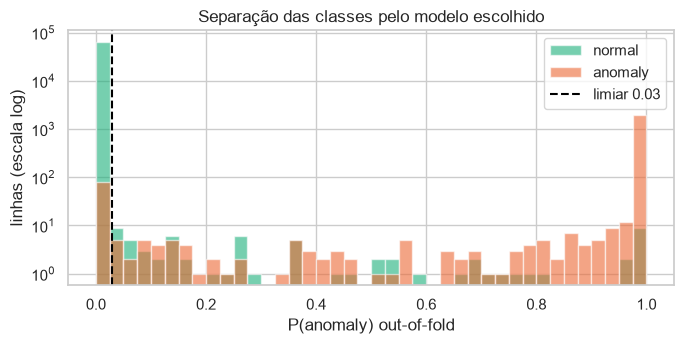

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0, 1, 41)
ax.hist(ev.loc[ev.classe != config.POSITIVE, "p"], bins=bins, alpha=0.6, color="#1baf7a",
        label="normal", log=True)
ax.hist(ev.loc[ev.classe == config.POSITIVE, "p"], bins=bins, alpha=0.6, color="#eb6834",
        label="anomaly", log=True)
ax.axvline(thr, color="black", ls="--", label=f"limiar {thr:.2f}")
ax.set_xlabel("P(anomaly) out-of-fold")
ax.set_ylabel("linhas (escala log)")
ax.set_title("Separação das classes pelo modelo escolhido")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "mod_probabilidades.png", dpi=150, bbox_inches="tight")
plt.show()

**O que se conclui.**
- **Quase todo erro está nos conflitos.** No OOF (limiar 0,03, F1-macro 0,8828), o modelo erra
  1.851 linhas, e 1.706 delas estão entre as 3.730 linhas com rótulo contraditório. Fora delas,
  erra 145 de 66.103 (F1-macro 0,983). O teto teórico, com acerto perfeito fora dos conflitos e o
  melhor rótulo possível em cada conflito, é 0,905: o modelo fica 0,02 abaixo dele.
- **Erros do modelo (fora dos conflitos):** deixa passar 3,7% dos ataques (81 falsos negativos em
  2.183) e alarma 0,1% das conexões normais (64 falsos positivos em 63.920).
- **Onde:** 60 dos 81 falsos negativos têm `flag=SF` (conexão concluída normalmente), a flag de
  95% do tráfego normal e de só 21% dos ataques. São ataques que imitam uma conexão comum: `private`
  (21), `ftp_data` (11), `telnet` (7), `http` (7). O perfil (serviços de login e transferência)
  sugere ataques de acesso remoto, cujo sinal está nos atributos de conteúdo (`hot`,
  `num_failed_logins`), e não nas janelas de tráfego. `private` concentra também os falsos
  positivos (31), o que mostra a sobreposição entre classes nesse serviço.
- **Limiar:** a curva tem um platô largo: o F1-macro fica a menos de 0,002 do máximo entre 0,01 e
  0,39. O limiar baixo (0,03 no OOF inteiro, 0,04 em média nos folds) vem dos conflitos: nos 1.376
  grupos empatados, prever `anomaly` rende mais F1-macro que prever `normal`, porque cada acerto na
  classe rara pesa mais. A escolha exata pesa pouco: em 0,5, o F1-macro cai só para 0,8803.
- O histograma mostra que a maioria das linhas tem probabilidade perto de 0 ou de 1. Os erros fora
  dos conflitos vivem numa faixa estreita de exemplos ambíguos, e é por isso que mais modelos no
  ensemble não resolvem: os erros não são aleatórios, são exemplos que os atributos não separam.

## 8. Escolha e congelamento do modelo final

Aplicando o critério declarado na Seção 1 à tabela de finalistas (CV 3×5):

In [21]:
winner = final_board.set_index("modelo").loc[chosen]
print(f"Maior F1-macro: {leader['modelo']} = {leader['f1_macro_mean']:.4f} "
      f"± {leader['f1_macro_std']:.4f}")
print(f"Empatados com ele (diferença < 1 dp): {tied['modelo'].tolist()}")
print(f"Escolhido (mais simples entre os empatados): {chosen} = "
      f"{winner['f1_macro_mean']:.4f} ± {winner['f1_macro_std']:.4f}")

Maior F1-macro: Voto HGB+XGB+RF = 0.8826 ± 0.0029
Empatados com ele (diferença < 1 dp): ['HGB busca 2', 'RF', 'HGB_native', 'LightGBM', 'HGB busca 2 + atributos', 'HGB + atributos', 'Voto HGB + LightGBM', 'Voto HGB + CatBoost', 'Voto HGB busca 2 ± atributos', 'Voto HGB+XGB+RF', 'Voto HGB + LightGBM + CatBoost', 'HGB busca 2, 5 sementes']
Escolhido (mais simples entre os empatados): HGB busca 2 = 0.8819 ± 0.0030


**Decisão: HGB da busca ampliada** (`HGB busca 2`). A maior média é a do voto HGB + XGB + RF
(0,8826), mas a diferença para o HGB (0,0007) é quatro vezes menor que o desvio entre folds. Pelo
critério declarado antes dos resultados, o empate vai para o mais simples: um modelo único, da
disciplina, sem passos extras. Ele treina em cerca de 1/9 do tempo do voto e pode ser explicado
diretamente na Etapa 4. Para o relatório, a leitura honesta é: *todos os candidatos de boosting
ficam perto de 0,882 e são equivalentes dentro do ruído; escolhemos o mais simples.*

Se a equipe preferir arriscar o voto triplo para tentar ganhar alguns décimos de milésimo no
ranking, a troca precisa ser feita **agora**, antes do notebook 04, e justificada como desvio do
critério declarado. Nós não recomendamos: o ganho esperado é indistinguível de zero.

O arquivo abaixo descreve o modelo final por completo. O notebook 04 reconstrói o pipeline a
partir dele, ajusta no treino inteiro (o `ThresholdClassifier` aprende o limiar por OOF dentro do
treino) e gera a submissão. Depois deste ponto, nenhuma escolha das Etapas 2 e 3 muda.

In [22]:
final_name = "HGB busca 2"
assert chosen == final_name, "o escolhido mudou: rever o texto desta seção"
final_config = {
    "model": "HGB_native",
    "model_params": hgb2[False],
    "pipeline_params": {k: v for k, v in cat["HGB_native"].items() if k != "balancing"},
    "threshold": "ThresholdClassifier: limiar de maior F1-macro nas previsões OOF "
                 "(StratifiedGroupKFold 5, agrupado por duplicata, todas as linhas) do próprio treino",
    "cv_f1_macro": float(winner["f1_macro_mean"]),
    "cv_f1_macro_std": float(winner["f1_macro_std"]),
    "cv_protocolo": "StratifiedGroupKFold 5 folds x 3 repetições (sementes 42-44), agrupado por "
                    "duplicata; F1-macro em todas as linhas do fold (como a métrica oficial), "
                    "limiar aprendido nos outros folds",
    "cv_f1_macro_sem_conflitos": float(winner["f1_macro_clean_mean"]),
    "cv_threshold_medio": float(winner["threshold_mean"]),
    "criterio": "maior F1-macro em CV agrupada 3x5; empate (< 1 dp) pelo mais simples",
    "random_state": config.RANDOM_STATE,
    "features": "41 atributos de rede (config.FEATURES); sem colunas de vazamento nem derivadas",
    "data_version": log.data_version,
    "data_congelamento": date.today().isoformat(),
}
(config.RESULTS / "final_config.json").write_text(
    json.dumps(final_config, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(final_config, indent=2, ensure_ascii=False))

{
  "model": "HGB_native",
  "model_params": {
    "min_samples_leaf": 20,
    "max_leaf_nodes": 63,
    "max_iter": 500,
    "max_features": 0.7,
    "learning_rate": 0.08,
    "l2_regularization": 0.0
  },
  "pipeline_params": {
    "redundancy": "drop_inconsistent",
    "domain": "nan",
    "imputation": "none",
    "scaling": "none",
    "log_transform": false,
    "service_encoding": "ordinal",
    "categorical_encoding": "ordinal"
  },
  "threshold": "ThresholdClassifier: limiar de maior F1-macro nas previsões OOF (StratifiedGroupKFold 5, agrupado por duplicata, todas as linhas) do próprio treino",
  "cv_f1_macro": 0.8819,
  "cv_f1_macro_std": 0.003,
  "cv_protocolo": "StratifiedGroupKFold 5 folds x 3 repetições (sementes 42-44), agrupado por duplicata; F1-macro em todas as linhas do fold (como a métrica oficial), limiar aprendido nos outros folds",
  "cv_f1_macro_sem_conflitos": 0.9817,
  "cv_threshold_medio": 0.044,
  "criterio": "maior F1-macro em CV agrupada 3x5; empate (< 1 

Verificação: o pipeline reconstruído a partir do arquivo é o mesmo que foi avaliado na CV (mesma
chave no registro de experimentos).

In [23]:
saved = json.loads((config.RESULTS / "final_config.json").read_text(encoding="utf-8"))
rebuilt = build_pipeline(make_model(saved["model"], 1, **saved["model_params"]),
                         **saved["pipeline_params"])
found = log.lookup("etapa3_final", final_name, rebuilt, {"redundancy": clean, "repeticoes": 3},
                   n_splits=5, n_repeats=3)
print("Pipeline reconstruído = pipeline avaliado:", found is not None)
rebuilt

Pipeline reconstruído = pipeline avaliado: True


,steps,"[('redundancy', ...), ('domain', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function _re...0021307385D00>
,kw_args,{'strategy': 'drop_inconsistent'}
,validate,False
,accept_sparse,True
,strategy,'nan'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('service', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False


## 9. Conclusões

| Pergunta | Resposta |
|---|---|
| Melhor família | boosting de árvores (HGB e LightGBM empatados), com RF e os votos no empate |
| Modelo final | HGB com categorias e NaN nativos, `drop_inconsistent`, limiar por OOF |
| F1-macro esperado (CV 3×5, todas as linhas) | **0,8819 ± 0,0030** |
| Contraste sem conflitos | 0,9817 (mesmo modelo, linhas únicas e sem rótulo contraditório) |
| Teto teórico da métrica | 0,905 (acerto perfeito fora dos conflitos, melhor rótulo em cada conflito) |
| O que mais rendeu | limpeza de rótulos no boosting (Etapa 2) e limiar de decisão |
| O que não rendeu | balanceamento, redução, ensembles, atributos derivados, CatBoost e o tuning |
| Erros restantes | 92% caem nas linhas com rótulo contraditório; o resto são ataques com `flag=SF` que imitam tráfego normal |

**Expectativa para o teste.** A professora calcula o F1-macro em *todas* as linhas do teste, como
a nossa validação. Se o teste tiver cópias e rótulos contraditórios na mesma proporção do treino,
o número oficial deve ficar perto de 0,88. Se tiver menos conflitos, pode ficar acima, até perto
do valor sem conflitos (0,98). O ruído vale igualmente para todas as equipes e não muda a ordem
dos modelos.

**Próximo passo (Etapa 4).** O notebook 04 lê `results/final_config.json`, ajusta o
`ThresholdClassifier(pipeline)` no treino inteiro, carrega o teste uma única vez
(`load_test(final_evaluation=True)`), gera `results/submissao_7.csv` e registra o SHA-256 do
arquivo. Em seguida vem a explicabilidade do modelo.

### Auditoria de vazamento deste notebook

`python -m nslkdd.audit notebooks/03_modelagem.ipynb` deve retornar **0 erros**. Nenhuma célula
carrega o teste, concatena bases ou ajusta transformações fora do pipeline. Os atributos
derivados da Seção 4 são calculados por uma regra fixa por linha (`FeatureBuilder`, testada em
`tests/test_leakage.py`), e o limiar de decisão é sempre escolhido em previsões out-of-fold.